# Charge-to-Mass Ratios and Millikan's Oil Drop

Two Ch. 37 questions:

1. *Which has a charge-to-mass ratio different from the others: ²H⁺, a proton, ⁶Li³⁺, an alpha particle?*
2. *A $1.00\times10^{-17}$ kg oil drop is suspended with 40.8 V. What is its charge?*

Both are worked symbolically (SymPy) and numerically, with **modern references** for the
constants. Module: [`dgs/charge_to_mass.py`](../dgs/charge_to_mass.py)

**References (IEEE)**
1. E. Tiesinga, P. J. Mohr, D. B. Newell, and B. N. Taylor, "CODATA recommended values of the fundamental physical constants: 2018," *Rev. Mod. Phys.*, vol. 93, no. 2, Art. no. 025010, 2021.
2. M. Wang, W. J. Huang, F. G. Kondev, G. Audi, and S. Naimi, "The AME 2020 atomic mass evaluation (II). Tables, graphs and references," *Chin. Phys. C*, vol. 45, no. 3, Art. no. 030003, 2021.
3. J. J. Thomson, "Cathode rays," *Philos. Mag.*, vol. 44, no. 269, pp. 293–316, 1897.
4. R. A. Millikan, "On the elementary electrical charge and the Avogadro constant," *Phys. Rev.*, vol. 2, no. 2, pp. 109–143, 1913.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.charge_to_mass import (
    PARTICLES, textbook_ratio, precise_ratio, ratio_si, odd_one_out, binding_energy_MeV,
    thomson_symbolic, thomson_deflection, millikan_symbolic, millikan_charge, is_physical_charge,
)

# 1. Charge-to-mass: the textbook answer

Use charge in units of $e$ and mass ≈ mass number $A$ in atomic mass units (u). SymPy keeps
the ratios as exact fractions:

In [2]:
t = {k: textbook_ratio(k) for k in PARTICLES}
pd.DataFrame([{"particle": k, "charge (e)": PARTICLES[k]["q"], "A (u)": PARTICLES[k]["A"], "q/A (e/u)": str(v)} for k, v in t.items()])

,particle,charge (e),A (u),q/A (e/u)
0,2H+ ion (deuteron),1,2,1/2
1,proton,1,1,1
2,6Li3+ ion,3,6,1/2
3,alpha particle,2,4,1/2


In [3]:
print("odd one out:", odd_one_out(t))

odd one out: proton


**The proton** is the only one at 1 e/u. The other three have one proton's worth of charge for
every *two* nucleons, because their nuclei hold equal numbers of protons and neutrons.

# 2. The precision twist: binding energy

Real nuclei weigh *less* than their parts. The missing mass is the nuclear binding energy,
$B = \Delta m\,c^2$. With CODATA 2018 [1] and AME2020 [2] masses, the three "½" particles
don't quite match:

In [4]:
rows = []
for k, p in PARTICLES.items():
    rows.append({"particle": k, "nuclear mass (u)": p["m_u"], "q/m (e/u)": precise_ratio(k),
                 "q/m (C/kg)": ratio_si(k), "deviation from q/A (%)": 100*(precise_ratio(k)/float(textbook_ratio(k)) - 1)})
display(pd.DataFrame(rows).round(6))
from dgs.charge_to_mass import M_ALPHA_U, M_DEUTERON_U
print(f"binding energy: deuteron {binding_energy_MeV(1, 1, M_DEUTERON_U):.3f} MeV,  "
      f"6Li {binding_energy_MeV(3, 3, PARTICLES['6Li3+ ion']['m_u']):.2f} MeV,  alpha {binding_energy_MeV(2, 2, M_ALPHA_U):.2f} MeV")

,particle,nuclear mass (u),q/m (e/u),q/m (C/kg),deviation from q/A (%)
0,2H+ ion (deuteron),2.013553,0.496635,4.791795e+07,-0.673099
1,proton,1.007276,0.992776,9.578833e+07,-0.722390
2,6Li3+ ion,6.013477,0.498879,4.813455e+07,-0.224116
3,alpha particle,4.001506,0.499812,4.822451e+07,-0.037640


binding energy: deuteron 2.225 MeV,  6Li 31.99 MeV,  alpha 28.30 MeV


The alpha is the most tightly bound per nucleon (28.3 MeV total), so it's the lightest per
nucleon and has the **largest** q/m of the three. The differences are only a few tenths of a
percent, too small for Thomson but easy for a modern mass spectrometer. The quiz answer
(proton) is unaffected: it differs by a factor of about 2.

# 3. How q/m is measured: Thomson's crossed fields

Thomson [3] sent charged particles through crossed $E$ (V/m) and $B$ fields. Particles pass
undeflected only when the electric and magnetic forces cancel, $qE = qvB$, so the setup
**selects** $v = E/B$. Switching $B$ off then deflects them by $y$ over a plate length $L$:

<IPython.core.display.Math object>

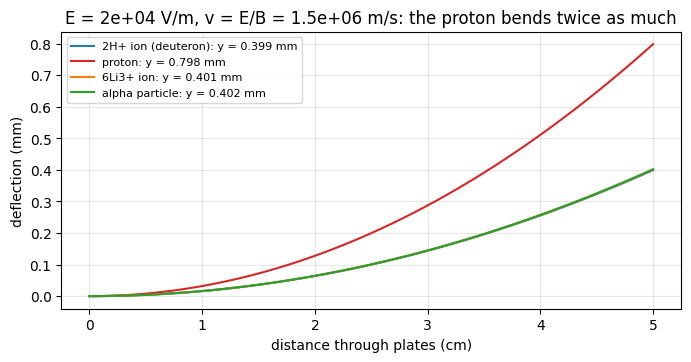

In [5]:
v_sel, y_expr, qm = thomson_symbolic()
display(Math(r"v = " + sp.latex(v_sel) + r",\quad y = " + sp.latex(y_expr) + r"\;\Rightarrow\; \frac{q}{m} = " + sp.latex(qm)))
E, B, L = 1.5e4, 0.01, 0.05
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, col in zip(PARTICLES, ("C0", "C3", "C1", "C2")):
    yd, v = thomson_deflection(ratio_si(k), E, B, L)
    xs = np.linspace(0, L, 100); ax.plot(xs*100, 0.5*ratio_si(k)*E*(xs/v)**2*1000, col, label=f"{k}: y = {yd*1000:.3f} mm")
ax.set(xlabel="distance through plates (cm)", ylabel="deflection (mm)", title=f"E = {E:.0e} V/m, v = E/B = {E/B:.1e} m/s: the proton bends twice as much")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

# 4. Millikan's drop, and a flaw in the question

A drop hangs still when the electric force balances gravity: $qE = mg$, with $E = V/d$ for
plates a distance $d$ apart. **The question gives the voltage but not $d$**, so the charge
depends on a number that isn't there:

In [6]:
expr, (m, g, V, d) = millikan_symbolic()
display(Math(r"q = " + sp.latex(expr)))
print(f"{'plate spacing d':>16s} {'q (C)':>12s} {'q / e':>8s}  whole number?")
for dd in (0.01, 0.05, 0.10, 0.50, 1.00):
    q, n = millikan_charge(1.00e-17, 40.8, dd)
    print(f"{dd:13.2f} m  {q:12.3e} {n:8.2f}  {is_physical_charge(n)}")

<IPython.core.display.Math object>

 plate spacing d        q (C)    q / e  whole number?
         0.01 m     2.402e-20     0.15  False
         0.05 m     1.201e-19     0.75  False
         0.10 m     2.402e-19     1.50  False
         0.50 m     1.201e-18     7.50  False
         1.00 m     2.402e-18    14.99  True


The intended reading is almost certainly that 40.8 is the **field**, $E = 40.8$ V/m
(the same as $d = 1.00$ m). That gives a whole number of electron charges matching an option: **15e**.

$$q = \frac{mg}{E} = \frac{(1.00\times10^{-17}\ \text{kg})(9.80\ \text{m/s}^2)}{40.8\ \text{V/m}} = 2.40\times10^{-18}\ \text{C} = 15.0\,e$$

The "1.5e" option (what $d = 10$ cm would give) is a **trap**. Millikan's result [4] is that
charge only comes in whole multiples of $e$, so a drop *cannot* carry 1.5e.

**Be honest about what quantization does and doesn't decide.** It *eliminates* 1.5e, but the
table below shows 5e, 10e and 20e are also whole numbers, each for a different plate spacing.
Strictly, the question is **underdetermined** without $d$. 15e is the answer under the
"40.8 V/m" reading, which is the only one that uses the numbers as given.

In [7]:
print("options checked against charge quantization:")
for n in (20, 10, 1.5, 5, 15):
    q = n*1.602176634e-19; d_needed = q*40.8/(1.00e-17*9.80)
    print(f"  {n:>4}e  whole number: {str(is_physical_charge(n)):5s}  would need d = {d_needed:6.3f} m")

options checked against charge quantization:
    20e  whole number: True   would need d =  1.334 m
    10e  whole number: True   would need d =  0.667 m
   1.5e  whole number: False  would need d =  0.100 m
     5e  whole number: True   would need d =  0.334 m
    15e  whole number: True   would need d =  1.001 m


## Exercises
1. Which has the largest q/m of all: an electron, a proton, or an alpha? By what factor?
2. A ³He²⁺ ion: is its q/A equal to ½? Compute it.
3. With $d = 1.0$ cm (a realistic Millikan gap), what voltage would hold a $1.00\times10^{-17}$ kg drop carrying 15e?
4. Write one sentence you could send your instructor pointing out that the oil-drop question omits $d$.